# Merge IRGA75 Level-1 fluxes without self-heating correction (2004-2017, 2019)

**notebook version**: `2` (28 Oct 2026)

## ℹ️ About this notebook

Merges the EddyPro *FLUXNET* output files of the **Level-1** (final) flux calculations for the
open-path **IRGA75** gas analyser into one continuous 30MIN dataframe and stores it in the external
data folder as parquet. The fluxes are **not corrected for self-heating** (`noSHC`); the correction is
Level 1.1.

No value is computed or corrected here. Three things change in the incoming data:

- Where two runs overlap, each record is taken whole from one of them, split at midnight (see the
  timestamp section below).
- The six biomet columns that every run exported are dropped.
- Columns that hold no value anywhere in the merged record are dropped.

The index is continuous from the first to the last record, so 2018, when no `IRGA75` was installed,
is part of it as empty records.

***

## 📇 Data sources

EddyPro *FLUXNET* output files (`*_adv.csv`), one per processing run, in the external data folder
under `00_DATA/IRGA75-Level-1_fluxnet_2004-2017+2019_noSHC/`.

A run covers one or more **setup periods**, not a calendar year. The merge therefore works on the
timestamps inside the files, not on the file names. The setup periods are documented in
`docs/Yearly_Notes.md`. Two runs span setup periods that are not adjacent:

- **`2005_1+4`** covers setup periods 1 and 4 of 2005. Periods 2 and 3 are the separate runs
  `2005_2` and `2005_3`, which lie in the gap of `2005_1+4` from 30 September to 12 November 2005.
- **`2008_1+4`** covers setup periods 1 and 4 of 2008. Periods 2 and 3 are the run `2008_2+3`,
  which lies in the gap of `2008_1+4` from 16 May to 30 June 2008.

The LI-7500 was removed in December 2017. **`2019_3`** (17 January to 20 March 2019) is a stand-in
run: both LI-7200 units were defective, and the LI-7500 measured again with the same sonic
anemometer.

**The biomet columns.** Every run exported its six biomet inputs (`TA_1_1_1`, `RH_1_1_1`,
`PA_1_1_1`, `SW_IN_1_1_1`, `LW_IN_1_1_1`, `PPFD_IN_1_1_1`) into the FLUXNET file. They are dropped:
the meteo variables come from the `10_METEO` products, not from the EddyPro output.

## 🕐 Timestamp convention and run overlaps

The EddyPro output carries `TIMESTAMP_START` and `TIMESTAMP_END`. Each file is read with
`output_middle_timestamp=True`, so the merged record is indexed on `TIMESTAMP_MIDDLE`, the same
convention as the Level-0 merge and the meteo products. Timestamps are used as written by EddyPro;
nothing is shifted here.

**Runs that meet at a year boundary overlap by up to six hours**, because both include the raw file
that spans midnight. They are separate runs and their values there differ. `MultiDataFileReader`
merges several files with `combine_first`, cell by cell, so a single record could combine `FC` from
one run with `LE` from the other. Each run is therefore read on its own, and each record is taken
whole from one run: records before midnight from the earlier run, records from midnight on from the
later one.

**A run's own records** are the rows its file holds. The reader puts every run on a continuous
index, so the gaps inside a run become empty rows; in `2005_1+4` and `2008_1+4` these span the runs
of the setup periods between. Overlaps are therefore taken between the own records of every pair of
runs, not only between runs next to each other in time.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
# The Level-1 EddyPro FLUXNET output files. They live in the external (untracked) data folder and
# are addressed by absolute path, so the notebook does not depend on the working directory.
SOURCEDIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\workflow\00_DATA\IRGA75-Level-1_fluxnet_2004-2017+2019_noSHC")
SOURCEPATTERN = "*_adv.csv"  # the FLUXNET output files; anything else in that folder is ignored
FILETYPE = 'EDDYPRO-FLUXNET-CSV-30MIN'

# The runs expected in SOURCEDIR, named by the part of the file name before '_eddypro', in time
# order of their first record.
EXPECTED_RUNS = [
    '2004_IRGA75', '2005_1+4_IRGA75', '2005_2_IRGA75', '2005_3_IRGA75', '2006_IRGA75',
    '2007_IRGA75', '2008_1+4_IRGA75', '2008_2+3_IRGA75', '2009_IRGA75', '2010_IRGA75',
    '2011_IRGA75', '2012_IRGA75', '2013_IRGA75', '2014_IRGA75', '2015_IRGA75',
    '2016_2+3_IRGA75', '2017_1+2_IRGA75', '2019_3_IRGA75',
]

# --- Output ------------------------------------------------------------------------------------
# Data files carry the same numeric prefix and the same relative path as the notebook producing
# them, in the external data folder.
OUTNAME = "99_IRGA75_L1_MERGED_noSHC_2004-2017_2019"
OUTPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\20_L1_FLUXES\IRGA75")

# --- Biomet columns ----------------------------------------------------------------------------
# Every Level-1 run wrote its biomet inputs into the EC output. They belong to the meteo products
# in 10_METEO. The drop is guarded below by a scan of the source file headers.
DROPCOLS = ['TA_1_1_1', 'RH_1_1_1', 'PA_1_1_1', 'SW_IN_1_1_1', 'LW_IN_1_1_1', 'PPFD_IN_1_1_1']

# --- Checks ------------------------------------------------------------------------------------
REQUIRED_TIME_RESOLUTION = '30min'
# The longest overlap two runs may have: one six-hour raw file. A longer one means a duplicated or
# misnamed run rather than a shared boundary file.
MAX_OVERLAP_RECORDS = 12
# Stretches longer than LONG_GAP_DAYS that no run covers, as (first, last) missing
# TIMESTAMP_MIDDLE: 2018, between the removal of the LI-7500 and the 2019 stand-in run. Any other
# gap of that length raises. Shorter gaps are listed in a table.
LONG_GAP_DAYS = 30
EXPECTED_LONG_GAPS = [('2018-01-01 01:15', '2019-01-17 13:15')]
EXPECTED_YEARS = list(range(2004, 2018)) + [2019]  # every year the merged record must carry FC for
FLUXCOLS = ['FC', 'LE', 'H']

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import textwrap
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from diive.core.io.filereader import search_files, MultiDataFileReader
from diive.core.io.files import save_parquet, load_parquet

pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
# The reader builds its frames column by column and warns about fragmentation on every file.
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-28 21:18:37
diive version: v0.93.0


## 📂 Source files

In [3]:
sourcefiles = search_files(searchdirs=SOURCEDIR, pattern=SOURCEPATTERN)

# An empty result reads exactly like a folder that has not been updated yet, so it raises instead
# of merging nothing and writing an empty product.
assert len(sourcefiles) > 0, f"no files matching {SOURCEPATTERN} found in {SOURCEDIR}"

_found = {_f.name.split('_eddypro')[0]: _f for _f in sourcefiles}
assert len(_found) == len(sourcefiles), "two source files share a run label"
assert sorted(_found) == sorted(EXPECTED_RUNS), (
    f"the runs found are not EXPECTED_RUNS. "
    f"Missing: {sorted(set(EXPECTED_RUNS) - set(_found))}; "
    f"not expected: {sorted(set(_found) - set(EXPECTED_RUNS))}")
RUNS = {_run: _found[_run] for _run in EXPECTED_RUNS}

print(f"Found {len(RUNS)} runs in {SOURCEDIR}:")
for _run, _f in RUNS.items():
    print(f"  {_run:<22} {_f.name}")

Found 18 runs in F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\00_DATA\IRGA75-Level-1_fluxnet_2004-2017+2019_noSHC:
  2004_IRGA75            2004_IRGA75_eddypro_CH-LAE_2004_FR-20261025-015217_fluxnet_2026-10-25T153218_adv.csv
  2005_1+4_IRGA75        2005_1+4_IRGA75_eddypro_CH-LAE_2005_1+4_FR-20261025-014900_fluxnet_2026-10-25T172619_adv.csv
  2005_2_IRGA75          2005_2_IRGA75_eddypro_CH-LAE_2005_2_FR-20261026-082007_fluxnet_2026-10-26T090437_adv.csv
  2005_3_IRGA75          2005_3_IRGA75_eddypro_CH-LAE_2005_3_FR-20261026-081729_fluxnet_2026-10-26T102603_adv.csv
  2006_IRGA75            2006_IRGA75_eddypro_CH-LAE_2006_FR-20261025-014531_fluxnet_2026-10-25T191347_adv.csv
  2007_IRGA75            2007_IRGA75_eddypro_CH-LAE_2007_FR-20261025-014245_fluxnet_2026-10-25T193348_adv.csv
  2008_1+4_IRGA75        2008_1+4_IRGA75_eddypro_CH-LAE_2008_1+4_FR-20261025-013712_fluxnet_2026-10-25T173840_adv.csv
  2008_2+3_IRGA75        2008_2+3_IRGA75_eddypro_CH-L

## 🧹 The biomet columns

The guard reads the header of every source file. All runs must carry the six biomet columns, and no
run may carry another column of the same `_1_1_1` form, which would be a biomet input this list
does not know about.

In [4]:
for _run, _f in RUNS.items():
    with open(_f, encoding='utf-8') as _fh:
        _header = _fh.readline().strip().split(',')
    _biomet = [_c for _c in _header if _c.endswith('_1_1_1')]
    assert sorted(_biomet) == sorted(DROPCOLS), (
        f"{_run} carries the biomet columns {sorted(_biomet)}, expected exactly {sorted(DROPCOLS)}")
print(f"All {len(RUNS)} runs carry exactly the {len(DROPCOLS)} biomet columns: {', '.join(DROPCOLS)}")

All 18 runs carry exactly the 6 biomet columns: TA_1_1_1, RH_1_1_1, PA_1_1_1, SW_IN_1_1_1, LW_IN_1_1_1, PPFD_IN_1_1_1


## 🔗 Read the runs

In [5]:
%%time
# One reader per run, so that no two runs are merged cell by cell (see the timestamp section). The
# reader puts each run on a continuous index; a run's own records are the rows its file holds, i.e.
# the rows with at least one value.
runs = {}
for _run, _f in RUNS.items():
    _df = MultiDataFileReader(filepaths=[_f], filetype=FILETYPE, output_middle_timestamp=True).data_df
    runs[_run] = _df.dropna(how='all')

> Reading file 
2004_IRGA75_eddypro_CH-LAE_2004_FR-20261025-015217_fluxnet_2026-10-25T153218_adv.csv ...

> Reading file 
2005_1+4_IRGA75_eddypro_CH-LAE_2005_1+4_FR-20261025-014900_fluxnet_2026-10-25T172619_adv.csv ...

> Reading file 
2005_2_IRGA75_eddypro_CH-LAE_2005_2_FR-20261026-082007_fluxnet_2026-10-26T090437_adv.csv ...

> Reading file 
2005_3_IRGA75_eddypro_CH-LAE_2005_3_FR-20261026-081729_fluxnet_2026-10-26T102603_adv.csv ...

> Reading file 
2006_IRGA75_eddypro_CH-LAE_2006_FR-20261025-014531_fluxnet_2026-10-25T191347_adv.csv ...

...

> Reading file 
2015_IRGA75_eddypro_CH-LAE_2015_FR-20261023-153526_fluxnet_2026-10-24T122059_adv.csv ...

> Reading file 
2016_2+3_IRGA75_eddypro_CH-LAE_2016_2+3_FR-20261023-153227_fluxnet_2026-10-24T183852_adv.csv ...

> Reading file 
2017_1+2_IRGA75_eddypro_CH-LAE_2017_1+2_FR-20261023-150135_fluxnet_2026-10-24T173450_adv.csv ...

> Reading file 
2019_3_IRGA75_eddypro_CH-LAE_2019_3_FR-20261023-145907_fluxnet_2026-10-23T191306_adv.csv ...

CPU times: total: 59.1 s
Wall time: 1min


### 📋 Table: the runs as read

In [6]:
_rows = []
for _run, _df in runs.items():
    _rows.append({'run': _run, 'first': _df.index[0], 'last': _df.index[-1], 'records': len(_df),
                  **{_c: int(_df[_c].notna().sum()) if _c in _df else 0 for _c in FLUXCOLS},
                  'columns': _df.shape[1]})
RUNTABLE = pd.DataFrame(_rows).set_index('run')
tabcap("every run as read from its file: its first and last TIMESTAMP_MIDDLE, its own records, the "
       "records holding FC, LE and H, and its number of columns")
display(RUNTABLE)

_starts = RUNTABLE['first']
assert _starts.is_monotonic_increasing and _starts.is_unique, "EXPECTED_RUNS is not in time order"
for _run, _df in runs.items():
    assert not _df.index.duplicated().any(), f"{_run} has duplicate timestamps"
    _steps = _df.index.to_series().diff().dropna()
    assert (_steps % pd.Timedelta(REQUIRED_TIME_RESOLUTION) == pd.Timedelta(0)).all(), (
        f"{_run} has timestamps off the {REQUIRED_TIME_RESOLUTION} grid")
    assert RUNTABLE.loc[_run, 'FC'] > 0, f"{_run} carries no FC"

Table - every run as read from its file: its first and last TIMESTAMP_MIDDLE, its own records, the
records holding FC, LE and H, and its number of columns



,first,last,records,FC,LE,H,columns
run,,,,,,,
2004_IRGA75,2004-03-30 14:45:00,2005-01-01 04:45:00,13042,12019,11660,13042,485
2005_1+4_IRGA75,2004-12-31 23:15:00,2005-12-31 02:15:00,15150,14573,13620,15150,485
2005_2_IRGA75,2005-09-30 12:15:00,2005-10-11 11:15:00,526,441,398,526,485
2005_3_IRGA75,2005-10-11 12:15:00,2005-11-12 15:15:00,1532,1474,1443,1532,485
2006_IRGA75,2006-01-03 08:15:00,2007-01-01 04:45:00,17227,16098,15171,17227,485
2007_IRGA75,2006-12-31 23:15:00,2008-01-01 04:45:00,17263,16450,15038,17263,485
2008_1+4_IRGA75,2007-12-31 23:15:00,2009-01-01 00:45:00,15106,14240,12935,15106,485
2008_2+3_IRGA75,2008-05-16 18:15:00,2008-06-30 12:15:00,2137,2068,1970,2137,485
2009_IRGA75,2009-01-01 00:45:00,2010-01-01 04:45:00,17023,16196,14889,17023,485


## ✂️ Run overlaps

Every pair of runs whose own records overlap is split at midnight: records before it from the
earlier run, records from it on from the later run. The table reports what the choice decides: the
largest difference between the two runs over the records where both hold a value.

In [7]:
# KEEP[run] = (first, last) TIMESTAMP_MIDDLE taken from that run; None means the run's own end.
KEEP = {_run: [None, None] for _run in runs}
_rows = []
_names = list(runs)
for _i, _a in enumerate(_names):
    for _b in _names[_i + 1:]:  # _a starts before _b
        _ov = runs[_a].index.intersection(runs[_b].index)
        if len(_ov) == 0:
            continue
        assert len(_ov) <= MAX_OVERLAP_RECORDS, f"{_a} and {_b} overlap by {len(_ov)} records"
        # The overlap must be one stretch at the end of the earlier run and the start of the later.
        assert _ov[0] == runs[_b].index[0] and _ov[-1] == runs[_a].index[-1], (
            f"{_a} and {_b} overlap other than end to start")
        # The midnight at or before the last shared record; at most one midnight inside the overlap.
        _cut = _ov[-1].floor('D')
        assert _cut - _ov[0].floor('D') <= pd.Timedelta('1D'), (
            f"the overlap of {_a} and {_b} spans more than one midnight")
        # The labels sit at :15 and :45, so the cut falls between two records rather than on one.
        if (_ov < _cut).any():
            KEEP[_a][1] = _ov[_ov < _cut][-1]
        else:
            KEEP[_a][1] = runs[_a].index[runs[_a].index < _cut][-1]
        KEEP[_b][0] = _ov[_ov >= _cut][0]
        _row = {'earlier run': _a, 'later run': _b, 'from': _ov[0], 'to': _ov[-1],
                'records': len(_ov), 'from earlier': int((_ov < _cut).sum()),
                'from later': int((_ov >= _cut).sum())}
        for _c in FLUXCOLS:
            _x, _y = runs[_a].loc[_ov, _c], runs[_b].loc[_ov, _c]
            _d = (_x - _y).abs()[_x.notna() & _y.notna()]
            _row[f'max |d{_c}|'] = _d.max() if len(_d) else float('nan')
        _rows.append(_row)

OVERLAPS = pd.DataFrame(_rows)
tabcap("each overlap of two runs: its first and last TIMESTAMP_MIDDLE, how many of its records are "
       "taken from either run, and the largest absolute difference between the two runs in FC "
       "(umol m-2 s-1), LE and H (W m-2) where both hold a value")
display(OVERLAPS)

Table - each overlap of two runs: its first and last TIMESTAMP_MIDDLE, how many of its records are
taken from either run, and the largest absolute difference between the two runs in FC (umol m-2
s-1), LE and H (W m-2) where both hold a value



,earlier run,later run,from,to,records,from earlier,from later,max |dFC|,max |dLE|,max |dH|
0,2004_IRGA75,2005_1+4_IRGA75,2004-12-31 23:15:00,2005-01-01 04:45:00,12,2,10,0.48400,0.30350,0.01750
1,2006_IRGA75,2007_IRGA75,2006-12-31 23:15:00,2007-01-01 04:45:00,12,2,10,1.63300,0.09900,0.00000
2,2007_IRGA75,2008_1+4_IRGA75,2007-12-31 23:15:00,2008-01-01 04:45:00,12,2,10,0.01760,0.06950,0.00000
3,2008_1+4_IRGA75,2009_IRGA75,2009-01-01 00:45:00,2009-01-01 00:45:00,1,0,1,0.00020,0.00102,0.00000
4,2009_IRGA75,2010_IRGA75,2009-12-31 23:15:00,2010-01-01 04:45:00,12,2,10,0.00120,0.01780,0.00000
5,2010_IRGA75,2011_IRGA75,2010-12-31 23:15:00,2011-01-01 04:45:00,12,2,10,0.01427,0.06350,0.00060
6,2011_IRGA75,2012_IRGA75,2011-12-31 20:15:00,2012-01-01 01:45:00,12,8,4,1.49300,2.08000,0.00000
7,2012_IRGA75,2013_IRGA75,2012-12-31 20:15:00,2013-01-01 01:45:00,12,8,4,0.01320,0.02052,0.00000
8,2013_IRGA75,2014_IRGA75,2013-12-31 20:15:00,2014-01-01 01:45:00,12,8,4,0.01000,0.09489,0.00540
9,2014_IRGA75,2015_IRGA75,2014-12-31 20:15:00,2015-01-01 01:45:00,12,8,4,0.05600,1.73340,0.05300


## 🔗 Merge

In [8]:
_parts = []
for _run, _df in runs.items():
    _lo, _hi = KEEP[_run]
    _parts.append(_df.loc[_lo:_hi])  # label slicing, both ends included; None leaves that end open

df = pd.concat(_parts, axis=0, sort=False).sort_index()
assert not df.index.duplicated().any(), "a timestamp was taken from two runs"
# The stretches no run covers become rows of NaN, so that the index is continuous.
df = df.reindex(pd.date_range(df.index[0], df.index[-1], freq=REQUIRED_TIME_RESOLUTION,
                              name=df.index.name))
df = df.sort_index(axis=1)

df = df.drop(columns=DROPCOLS)
_empty = df.columns[df.notna().sum() == 0]
df = df.drop(columns=_empty)
print(f"Dropped the {len(DROPCOLS)} biomet columns and {len(_empty)} columns without any value:")
print(textwrap.fill(' '.join(_empty), 100))
print(f"\nRecords: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Period:  {df.index[0]} -> {df.index[-1]}  (index: {df.index.name})")

Dropped the 6 biomet columns and 173 columns without any value:
BADM_INSTPAIR_EASTWARD_SEP_GA_CH4 BADM_INSTPAIR_EASTWARD_SEP_GA_NONE BADM_INSTPAIR_HEIGHT_SEP_GA_CH4
BADM_INSTPAIR_HEIGHT_SEP_GA_NONE BADM_INSTPAIR_NORTHWARD_SEP_GA_CH4
BADM_INSTPAIR_NORTHWARD_SEP_GA_NONE BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_CH4
BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_CO2 BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_H2O
BADM_INST_GA_CP_TUBE_FLOW_RATE_GA_NONE BADM_INST_GA_CP_TUBE_IN_DIAM_GA_CH4
BADM_INST_GA_CP_TUBE_IN_DIAM_GA_CO2 BADM_INST_GA_CP_TUBE_IN_DIAM_GA_H2O
BADM_INST_GA_CP_TUBE_IN_DIAM_GA_NONE BADM_INST_GA_CP_TUBE_LENGTH_GA_CH4
BADM_INST_GA_CP_TUBE_LENGTH_GA_CO2 BADM_INST_GA_CP_TUBE_LENGTH_GA_H2O
BADM_INST_GA_CP_TUBE_LENGTH_GA_NONE BADM_INST_MODEL_GA_CH4 BADM_INST_MODEL_GA_CO2
BADM_INST_MODEL_GA_H2O BADM_INST_MODEL_GA_NONE BADM_INST_MODEL_SA BADM_INST_SA_GILL_ALIGN
BADM_INST_SA_WIND_FORMAT CH4 CH4_ABSLIM_NREX CH4_DIAG_NREX CH4_KID CH4_LGD CH4_MEAS_KUR
CH4_MEAS_MEDIAN CH4_MEAS_NONE_MEAS_COV CH4_MEAS_P25 CH4_MEAS_P75 CH4

## 🔍 Checks

In [9]:
# The index must be continuous 30MIN, unique and ascending.
assert df.index.is_monotonic_increasing, "timestamp index is not ascending"
assert not df.index.duplicated().any(), "duplicate timestamps in the merged record"
_steps = df.index.to_series().diff().dropna().unique()
assert len(_steps) == 1 and _steps[0] == pd.Timedelta(REQUIRED_TIME_RESOLUTION), \
    f"index is not continuous {REQUIRED_TIME_RESOLUTION}, found steps: {_steps}"
assert df.dtypes.map(pd.api.types.is_numeric_dtype).all(), "a non-numeric column reached the merge"

# Every record holds exactly the values of the run it was taken from. This is what reading the runs
# separately is for, so it is tested on the merged frame rather than assumed.
_covered = pd.Series(False, index=df.index)
for _run, _df in runs.items():
    _lo, _hi = KEEP[_run]
    _own = _df.loc[_lo:_hi]
    _covered.loc[_own.index] = True
    for _c in FLUXCOLS:
        if _c in _own:
            pd.testing.assert_series_equal(df.loc[_own.index, _c], _own[_c], check_names=False,
                                           obj=f"{_c} of {_run}")

# Every record that some run holds is in the merge: the overlap cuts drop nothing.
_held = pd.DatetimeIndex([])
for _df in runs.values():
    _held = _held.union(_df.index)
assert _covered.loc[_held].all(), (
    f"records held by a run are missing from the merge: {list(_held[~_covered.loc[_held].values])[:5]}")

# The stretches no run covers, longer than one day, as a table; those longer than LONG_GAP_DAYS must
# be exactly the explained ones.
_gap = ~_covered
_starts = df.index[_gap & ~_gap.shift(1, fill_value=False)]
_ends = df.index[_gap & ~_gap.shift(-1, fill_value=False)]
GAPS = pd.DataFrame({'first': _starts, 'last': _ends})
GAPS['length'] = GAPS['last'] - GAPS['first'] + pd.Timedelta(REQUIRED_TIME_RESOLUTION)
GAPS = GAPS[GAPS['length'] > pd.Timedelta('1D')].reset_index(drop=True)
_long = [(_s, _e) for _s, _e, _l in GAPS.itertuples(index=False) if _l > pd.Timedelta(days=LONG_GAP_DAYS)]
assert _long == [(pd.Timestamp(_s), pd.Timestamp(_e)) for _s, _e in EXPECTED_LONG_GAPS], (
    f"the gaps longer than {LONG_GAP_DAYS} days are not EXPECTED_LONG_GAPS: {_long}")

# A year can be present in the index and still be empty, so FC is counted per year.
_missing = [_y for _y in EXPECTED_YEARS if df.loc[df.index.year == _y, 'FC'].count() == 0]
assert not _missing, f"no FC for {_missing}, source file missing?"
print("Index, run provenance, gaps and years verified.")

Index, run provenance, gaps and years verified.


### 📋 Table: stretches longer than one day that no run covers

In [10]:
tabcap(f"every stretch longer than one day without a record from any run: its first and last missing "
       f"TIMESTAMP_MIDDLE and its length. Only the gaps longer than {LONG_GAP_DAYS} days are checked "
       f"against EXPECTED_LONG_GAPS")
display(GAPS)

Table - every stretch longer than one day without a record from any run: its first and last missing
TIMESTAMP_MIDDLE and its length. Only the gaps longer than 30 days are checked against
EXPECTED_LONG_GAPS



,first,last,length
0,2004-12-26 16:45:00,2004-12-28 09:45:00,1 days 17:30:00
1,2005-01-30 01:15:00,2005-01-31 09:45:00,1 days 09:00:00
2,2005-08-24 08:15:00,2005-08-25 10:15:00,1 days 02:30:00
3,2005-11-26 08:15:00,2005-11-28 08:45:00,2 days 01:00:00
4,2005-12-31 02:45:00,2006-01-03 07:45:00,3 days 05:30:00
5,2006-02-21 14:15:00,2006-02-23 10:15:00,1 days 20:30:00
6,2007-12-27 22:15:00,2007-12-29 06:15:00,1 days 08:30:00
7,2008-07-29 13:45:00,2008-07-30 14:15:00,1 days 01:00:00
8,2008-12-17 11:45:00,2008-12-18 17:45:00,1 days 06:30:00
9,2009-02-05 02:15:00,2009-02-06 08:45:00,1 days 07:00:00


### 📋 Table: flux records per year

In [11]:
_peryear = df[FLUXCOLS].groupby(df.index.year).count()
tabcap("half-hours holding FC, LE and H in each year of the merged record. 2004 begins on 30 March, "
       "2018 has no IRGA75 record, and 2019 holds the stand-in run of January to March")
display(_peryear)

Table - half-hours holding FC, LE and H in each year of the merged record. 2004 begins on 30 March,
2018 has no IRGA75 record, and 2019 holds the stand-in run of January to March



,FC,LE,H
TIMESTAMP_MIDDLE,,,
2004,12011,11656,13032
2005,16486,15459,17206
2006,16088,15166,17217
2007,16438,15027,17251
2008,16305,14903,17240
2009,16186,14879,17013
2010,15387,13974,16667
2011,15795,14899,17110
2012,14612,13081,16140


### 📊 Plot: daily flux records over the merged period

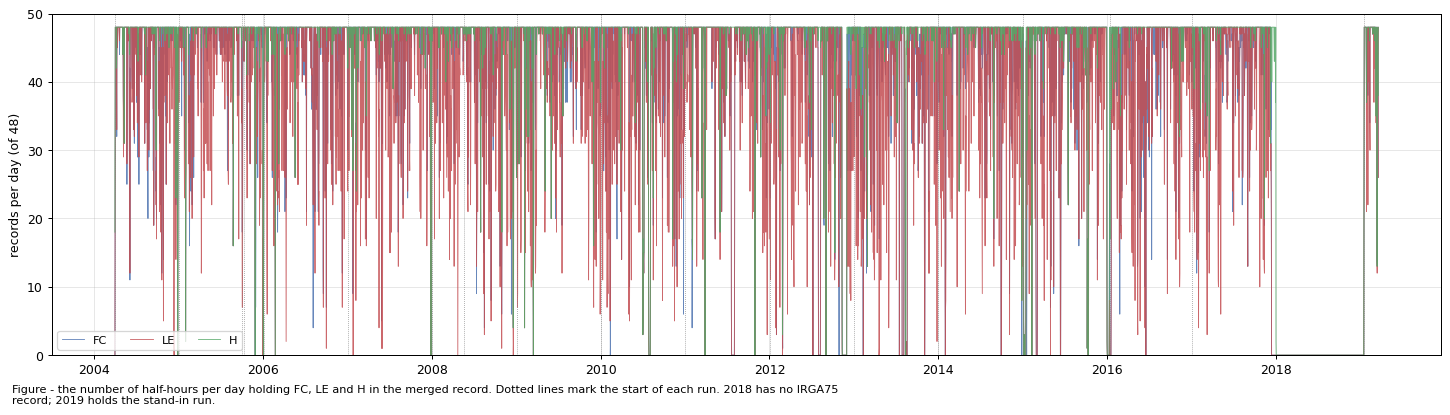

In [12]:
fig, ax = plt.subplots(figsize=(16, 4.5), dpi=90, layout='constrained')
for _c, _col in zip(FLUXCOLS, ['#4C72B0', '#C44E52', '#55A868']):
    _n = df[_c].resample('D').count()
    ax.plot(_n.index, _n.values, lw=0.7, color=_col, label=_c, alpha=.85)
for _run in runs:
    _lo = KEEP[_run][0] or runs[_run].index[0]
    ax.axvline(_lo, color='0.5', lw=0.6, ls=':')
ax.set_ylabel('records per day (of 48)')
ax.set_ylim(0, 50)
ax.legend(loc='lower left', ncol=3, fontsize=9)
ax.grid(alpha=.3)
figcap(fig, "the number of half-hours per day holding FC, LE and H in the merged record. Dotted lines "
            "mark the start of each run. 2018 has no IRGA75 record; 2019 holds the stand-in run.")
plt.show()

## 💾 Export

In [13]:
Path(OUTPATH).mkdir(parents=True, exist_ok=True)
filepath = save_parquet(filename=OUTNAME, data=df, outpath=OUTPATH)
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_L1_FLUXES\IRGA
75\99_IRGA75_L1_MERGED_noSHC_2004-2017_2019.parquet (3.902 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_L1_FLUXES\IRGA75\99_IRGA75_L1_MERGED_noSHC_2004-2017_2019.parquet


## ✅ Read the written file back

In [14]:
_written = load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"index:   {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"columns: {len(_written.columns):,}")

assert _written.index.equals(df.index), "index changed on write"
assert list(_written.columns) == list(df.columns), "columns changed on write"
for _c in FLUXCOLS:
    assert _written[_c].equals(df[_c]), f"{_c} changed on write"
print("\nWritten file verified.")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_L1_FLUXES\IRGA
75\99_IRGA75_L1_MERGED_noSHC_2004-2017_2019.parquet (0.872 seconds).

index:   2004-03-30 14:45:00 -> 2019-03-20 18:45:00  (262,473 records)
columns: 320

Written file verified.


***

# End of notebook.

In [15]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-28 21:18:37
Finished: 2026-10-28 21:19:46
Runtime:  00:01:08 (hh:mm:ss)
